# 🌊 Statistical Data Visualization with Seaborn — Complete Masterclass

> **Day 19 Transcripts**: Relational plots, categorical distributions, box plots, KDE distributions, heatmaps aur visualization best practices.

### 🗺️ Topics Index:
1. **Introduction to Seaborn** (`sns.set_theme()`, `relplot`)
2. **Relational Plots** (`scatterplot` with `hue` & `style`)
3. **Categorical Plots** (`barplot` with aggregated means)
4. **Distribution & Outlier Detection** (`boxplot`)
5. **Continuous Density Estimation** (`histplot` with `kde=True`)
6. **Correlation & Matrix Visualization** (`heatmap` with `annot=True`)


### Operation 1: Introduction to Seaborn & Relational Scatter (`relplot`)
- Matplotlib ke upar built statistical layer jo automatic semantic mapping (`hue`, `style`, `size`) provide karti hai.


Tips Dataset Preview (Total records: 150 ):


,total_bill,tip,sex,smoker,day,time,size
0,25.73,5.38,Male,Yes,Fri,Lunch,2
1,49.93,6.43,Female,No,Thur,Lunch,5
2,40.74,4.78,Female,Yes,Sat,Lunch,3
3,35.14,5.58,Female,No,Sat,Lunch,2


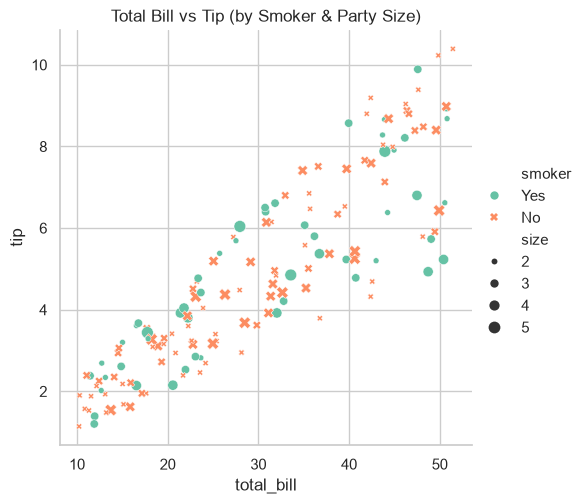

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set aesthetic theme
sns.set_theme(style="whitegrid")

# Realistic Tips Dataset (100% Offline Simulation)
np.random.seed(42)
n_samples = 150

bills = np.random.uniform(10.0, 52.0, n_samples)
tips_data = bills * np.random.uniform(0.10, 0.22, n_samples)

tips = pd.DataFrame({
    "total_bill": np.round(bills, 2),
    "tip": np.round(tips_data, 2),
    "sex": np.random.choice(["Male", "Female"], n_samples),
    "smoker": np.random.choice(["Yes", "No"], n_samples, p=[0.38, 0.62]),
    "day": np.random.choice(["Thur", "Fri", "Sat", "Sun"], n_samples),
    "time": np.random.choice(["Lunch", "Dinner"], n_samples, p=[0.3, 0.7]),
    "size": np.random.choice([2, 3, 4, 5], n_samples, p=[0.4, 0.3, 0.2, 0.1])
})

print("Tips Dataset Preview (Total records:", len(tips), "):")
display(tips.head(4))

# Multi-dimensional Relational Plot
sns.relplot(
    data=tips,
    x="total_bill", y="tip",
    hue="smoker", style="smoker", size="size",
    palette="Set2"
)
plt.title("Total Bill vs Tip (by Smoker & Party Size)")
plt.show()


### Operation 2: Dual Relational Scatter Comparison
- Category level partitioning across lunch vs dinner time slots.


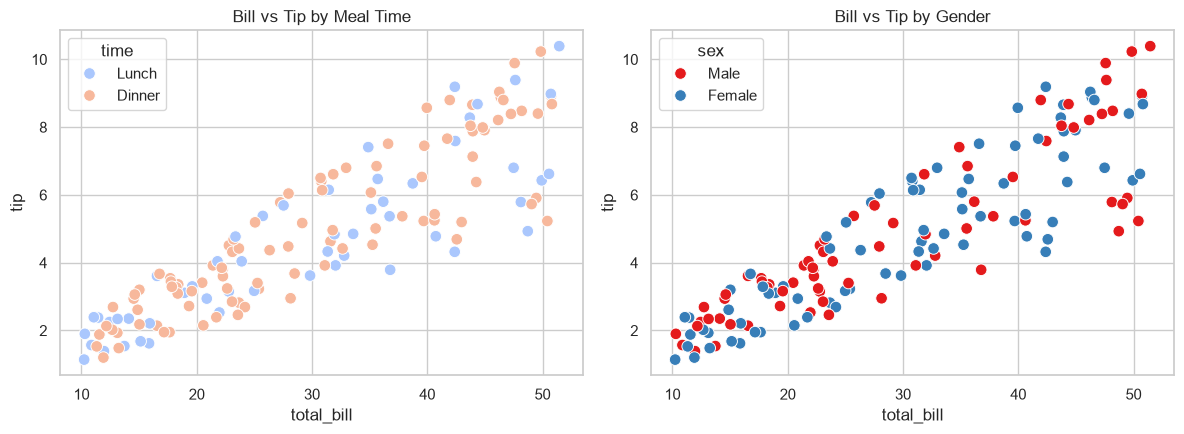

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Scatter with 'time' hue
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", palette="coolwarm", s=70, ax=ax1)
ax1.set_title("Bill vs Tip by Meal Time")

# 2. Scatter with 'sex' hue
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="sex", palette="Set1", s=70, ax=ax2)
ax2.set_title("Bill vs Tip by Gender")

plt.tight_layout()
plt.show()


### Operation 3: Categorical Aggregations (`barplot`)
- Automatic mean calculation aur category comparison across days.


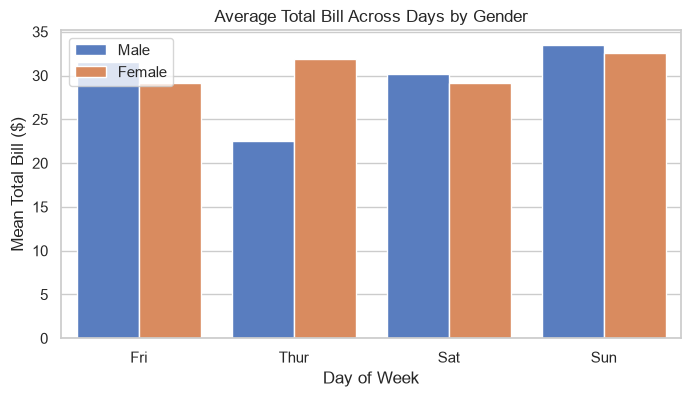

In [3]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=tips,
    x="day", y="total_bill",
    hue="sex",
    palette="muted",
    errorbar=None
)

plt.title("Average Total Bill Across Days by Gender")
plt.xlabel("Day of Week")
plt.ylabel("Mean Total Bill ($)")
plt.legend(loc="upper left")
plt.show()


### Operation 4: Outlier Detection with Box Plots (`boxplot`)
- Quartiles (Q1, Median, Q3), Interquartile Range (IQR) aur statistical outliers.


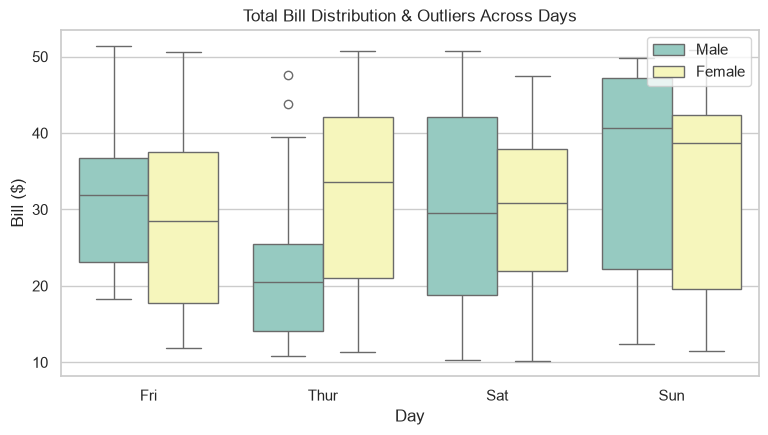

In [4]:
plt.figure(figsize=(9, 4.5))

sns.boxplot(
    data=tips,
    x="day", y="total_bill",
    hue="sex",
    palette="Set3"
)

plt.title("Total Bill Distribution & Outliers Across Days")
plt.xlabel("Day")
plt.ylabel("Bill ($)")
plt.legend(loc="upper right")
plt.show()


### Operation 5: Continuous Density Estimation (`histplot` with KDE)
- Frequency histogram ke sath smooth Kernel Density Estimation (KDE) curve overlay.


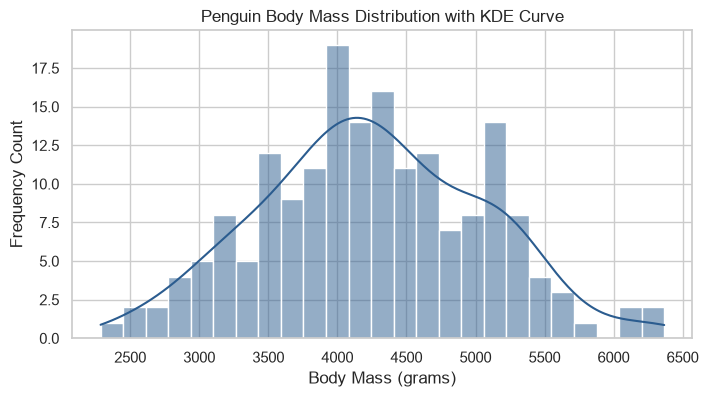

In [5]:
# Penguins Dataset (100% Offline Simulation)
np.random.seed(101)
n_penguins = 180

penguins = pd.DataFrame({
    "species": np.random.choice(["Adelie", "Chinstrap", "Gentoo"], n_penguins),
    "flipper_length_mm": np.random.normal(200, 15, n_penguins),
    "body_mass_g": np.random.normal(4200, 750, n_penguins)
})

plt.figure(figsize=(8, 4))

sns.histplot(
    data=penguins,
    x="body_mass_g",
    kde=True,
    bins=25,
    color="#2b5c8f"
)

plt.title("Penguin Body Mass Distribution with KDE Curve")
plt.xlabel("Body Mass (grams)")
plt.ylabel("Frequency Count")
plt.show()


### Operation 6: Correlation Matrix & Density Heatmap (`heatmap`)
- 2D Matrix intensity visualization with annotations (`annot=True`).


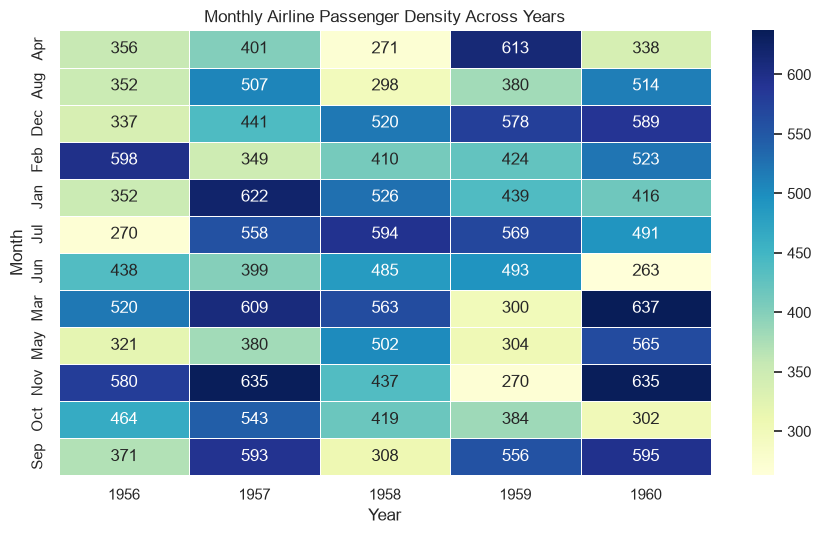

In [6]:
# Monthly Flight Passenger Density Matrix (100% Offline Simulation)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"] * 5
years = [y for y in [1956, 1957, 1958, 1959, 1960] for _ in range(12)]
np.random.seed(42)
passengers = np.random.randint(250, 650, size=60)
flights = pd.DataFrame({"month": months, "year": years, "passengers": passengers})

flights_pivot = flights.pivot(index="month", columns="year", values="passengers")

plt.figure(figsize=(9, 5.5))

sns.heatmap(
    flights_pivot,
    cmap="YlGnBu",
    annot=True,
    fmt="d",
    linewidths=0.5
)

plt.title("Monthly Airline Passenger Density Across Years")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.show()


---

## 🎯 Day 19 Summary Checklist
- [x] **Relational:** `sns.relplot()`, `scatterplot()` with multi-attribute mapping.
- [x] **Categorical:** `sns.barplot()` with automatic mean aggregation.
- [x] **Distribution:** `sns.boxplot()` IQR quartile analysis and outlier spotting.
- [x] **KDE Curve:** `sns.histplot(kde=True)` continuous probability density.
- [x] **Matrix Heatmap:** `sns.heatmap()` with numerical cell annotations.

---
### 🏆 Seaborn Statistical Visualization Completed!
